# Fase 0b — Datos externos: ONI, catálogo de estaciones y CHIRPS v2 original

En el EDA (`01_EDA_calidad_datos.ipynb`) quedaron tres pendientes:

1. **Índice ONI** para el codificador de la red y para el análisis por fase ENSO.
2. **Coordenadas y altitud** de las estaciones (para el emparejamiento estación–píxel y para `z`).
3. Los años **1985, 1988 y 2000**, muy secos en el satélite entregado pero no en las estaciones: ¿defecto del producto o clima?

Además se buscó si las series de estaciones existen completas en la web para **rellenar huecos**. Este notebook documenta qué se descargó, de dónde, qué se pudo usar y qué no.

| Archivo en `datos_web/` | Fuente | Cómo se obtuvo |
|---|---|---|
| `ONI_NOAA_CPC_1981_2013.csv` | NOAA CPC, `cpc.ncep.noaa.gov/data/indices/oni.ascii.txt` | Descarga directa (nov‑2026) |
| `CNE_IDEAM_dominio_satelite.csv` | Catálogo Nacional de Estaciones, datos.gov.co (`hp9r-jxuu`) | API Socrata, filtrado a la caja del satélite |
| `chirps_v2_valle_1981_2013.bin` + `_claves.txt` | CHIRPS v2.0 pentadal, `data.chc.ucsb.edu/products/CHIRPS/v2.0/global_pentad/cogs/` | Lectura por ventana de los COG (mismo recorte de 39×37 píxeles) |
| `nasa_power_PRECTOTCORR_valle_1981_2013.csv` | NASA POWER (reanálisis MERRA‑2), API diaria por punto | 20 nodos de 0,5°×0,625°, 1981–2013 |

In [1]:
# %pip install pandas numpy matplotlib rasterio
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, rasterio

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
ROOT = Path.cwd(); DW = ROOT / "datos_web"; OUT = ROOT / "eda_fase0"
SAT_DIR = ROOT / "ImagenesSatelitePentadal"
print({f.name: f"{f.stat().st_size/1e6:.2f} MB" for f in sorted(DW.glob("*"))})

{'chirps_v2_valle_1981_2013.bin': '13.71 MB', 'chirps_v2_valle_1981_2013_claves.txt': '0.03 MB', 'CNE_IDEAM_dominio_satelite.csv': '0.57 MB', 'nasa_power_PRECTOTCORR_valle_1981_2013.csv': '7.81 MB', 'ONI_NOAA_CPC_1981_2013.csv': '0.00 MB', 'oni_noaa_cpc_completo.txt': '0.02 MB'}


## 1. Índice ONI y fase ENSO de cada año

El ONI (*Oceanic Niño Index*) es la anomalía de temperatura superficial del mar en la región Niño 3.4, en medias móviles de 3 meses (DJF, JFM, …, NDJ). NOAA declara El Niño/La Niña cuando el ONI supera ±0,5 °C durante al menos 5 trimestres seguidos.

Como las curvas son **anuales (enero–diciembre)**, se resume cada año con la **media de sus 12 trimestres** y se clasifica: Niño si ≥ 0,5; Niña si ≤ −0,5; neutro en otro caso. Esa media es la que entraría en `z` junto a la altitud.

anio,1981,1982,1983,1984,1985,1986,1987,1988,1989,1990,...,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
ONI_anual,-0.25,0.91,0.46,-0.55,-0.58,0.27,1.18,-0.89,-0.62,0.27,...,0.39,0.03,0.04,-0.61,-0.81,0.26,-0.43,-0.77,-0.07,-0.26
fase,Neutro,Niño,Neutro,Niña,Niña,Neutro,Niño,Niña,Niña,Neutro,...,Neutro,Neutro,Neutro,Niña,Niña,Neutro,Neutro,Niña,Neutro,Neutro


1981‑2013: {'Neutro': 18, 'Niña': 9, 'Niño': 6} | 1981‑2003: {'Neutro': 11, 'Niño': 6, 'Niña': 6}


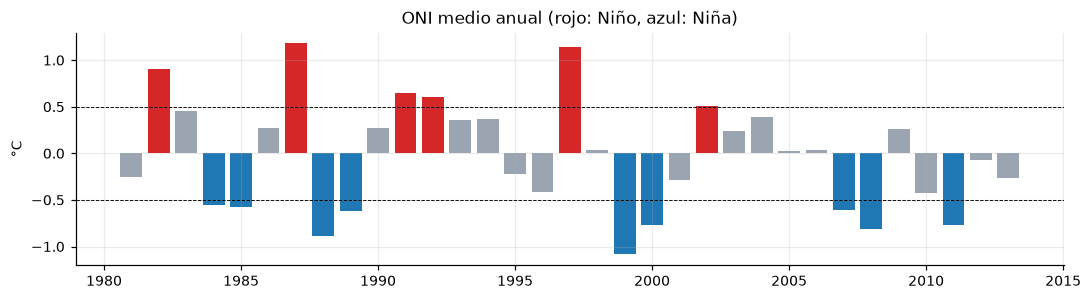

In [2]:
oni = pd.read_csv(DW / "ONI_NOAA_CPC_1981_2013.csv").set_index("anio")
oni["ONI_anual"] = oni.mean(axis=1).round(2)
oni["fase"] = np.select([oni.ONI_anual >= .5, oni.ONI_anual <= -.5], ["Niño", "Niña"], "Neutro")
display(oni[["ONI_anual", "fase"]].T)
print("1981‑2013:", oni.fase.value_counts().to_dict(), "| 1981‑2003:", oni.loc[1981:2003].fase.value_counts().to_dict())

fig, ax = plt.subplots(figsize=(10, 2.8))
col = oni.fase.map({"Niño": "#d62728", "Niña": "#1f77b4", "Neutro": "#9aa5b1"})
ax.bar(oni.index, oni.ONI_anual, color=col); ax.axhline(.5, ls="--", c="k", lw=.6); ax.axhline(-.5, ls="--", c="k", lw=.6)
ax.set(title="ONI medio anual (rojo: Niño, azul: Niña)", ylabel="°C"); plt.tight_layout(); plt.show()
oni[["ONI_anual", "fase"]].to_csv(OUT / "oni_anual_fase.csv")

**Lectura.** En 1981–2003 hay años de las tres fases, pero pocos de cada una (ver conteo arriba). Los análisis por fase ENSO tendrán bandas anchas; conviene reportarlos como descriptivos.

Con el ONI se puede revisar la observación del EDA: si 1985, 1988 y 2000 son años **La Niña** (lo son, según el ONI anual), en el occidente colombiano deberían ser lluviosos o normales, no secos.

## 2. Catálogo Nacional de Estaciones: ¿podemos ubicar nuestras estaciones?

El CNE trae código, nombre, entidad, categoría, coordenadas y altitud de todas las estaciones registradas en Colombia (IDEAM y otras entidades, incluida la CVC).

In [3]:
f_cne = DW / "CNE_IDEAM_dominio_satelite.csv"
if f_cne.exists():
    cne = pd.read_csv(f_cne, dtype={"codigo": str}, encoding="utf-8-sig")
    cne["cod8"] = cne.codigo.str[-8:]
    print(f"Estaciones del CNE dentro de la caja del satélite: {len(cne)}")
    display(cne.groupby("entidad").size().sort_values(ascending=False).head(8).to_frame("n"))
    display(cne.categoria.value_counts().to_frame("n").T)
else:
    cne = None
    print("Falta datos_web/CNE_IDEAM_dominio_satelite.csv (mover desde Descargas).")

Estaciones del CNE dentro de la caja del satélite: 2400


,n
entidad,
CORPORACION AUTONOMA REGIONAL DEL VALLE DEL CAUCA,820
INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIOS AMBIENTALES,482
ESTACIONES PARTICULARES,386
FEDERACIÓN NACIONAL DE CAFETEROS,238
INSTITUTO COLOMBIANO DE ENERGÍA ELÉCTRICA (ELECTRAGUAS),68
CENTRO NACIONAL DE INVESTIGACIÓN PARA LA CAÑA DE AZUCAR,54
CORPORACIÓN AUTÓNOMA REGIONAL DEL QUINDÍO,52
CENTRO NACIONAL DE INVESTIGACIONES DE CAFÉ,46


categoria,Pluviométrica,Climatológica Ordinaria,Limnigráfica,Limnimétrica,Climatológica Principal,Pluviográfica,Meteorológica Especial,Agrometeorológica,Sinóptica Principal,Meteorológica Marina,Ambiental,Radio Sonda,Sinóptica Secundaria
n,1194,288,268,246,186,136,42,12,12,6,4,4,2


In [4]:
# ¿Coinciden los códigos? Nuestros STATION_ID tienen 10 dígitos; los del CNE, 8.
raw = pd.read_pickle(OUT / "estaciones_crudas.pkl") if (OUT / "estaciones_crudas.pkl").exists() else None
ids = pd.Series(sorted(raw.STATION_ID.unique())).astype(str) if raw is not None else pd.Series(dtype=str)
if cne is not None and len(ids):
    pruebas = {"primeros 8 dígitos": ids.str[:8], "últimos 8 dígitos": ids.str[-8:],
               "sin los 2 últimos, con '0' final": ids.str[:7] + "0"}
    for nombre, cand in pruebas.items():
        print(f"{nombre:35s}: {cand.isin(cne.cod8).sum()} de {len(ids)} coinciden")
    print("\nEjemplos nuestros:", ids.head(4).tolist(), "| ejemplos CNE:", cne.cod8.head(4).tolist())

primeros 8 dígitos                 : 0 de 344 coinciden
últimos 8 dígitos                  : 0 de 344 coinciden
sin los 2 últimos, con '0' final   : 17 de 344 coinciden

Ejemplos nuestros: ['2610000101', '2610000102', '2610000103', '2610000104'] | ejemplos CNE: ['26090930', '26040150', '26120170', '26117120']


**Lectura.** Los códigos del proyecto (`2612000202`, 10 dígitos) **no siguen la codificación del CNE** (`26050110`, 8 dígitos) y no hay una regla que los convierta. La única regla con coincidencias (los 7 primeros dígitos más un 0) es falsa: asigna 17 estaciones nuestras distintas a solo dos códigos del CNE, que además son estaciones limnimétricas (nivel de río), no pluviómetros. Los dos primeros dígitos sí coinciden con el área/zona hidrográfica (26 = Cauca, 53–54 = Pacífico), pero eso no basta para ubicar una estación.

También se buscaron los códigos en la web, en el servidor geográfico de la CVC (no publica su capa de estaciones) y en datos.gov.co. No aparecen. **Las coordenadas y la altitud deben pedirse al docente.** El catálogo descargado sirve igual para:
- verificar cuando lleguen las coordenadas (deberían caer cerca de estaciones del CNE de la misma subzona);
- tener la altitud de referencia de la red en la zona.

**¿Rellenar huecos con datos de la web?** No es viable para 1981–2003:
- el conjunto de precipitación del IDEAM en datos.gov.co (`s54a-sgyg`) solo va de **2017 a 2026**;
- la descarga histórica masiva del IDEAM (`bart.ideam.gov.co`) no respondía, y DHIME exige descargar estación por estación;
- aunque se consiguieran, **sin un mapa de códigos no se sabe a cuál de nuestras estaciones corresponde cada serie**.
- Rellenar con el satélite (CHIRPS) tampoco es aceptable: contaminaría justamente la comparación estación–satélite.

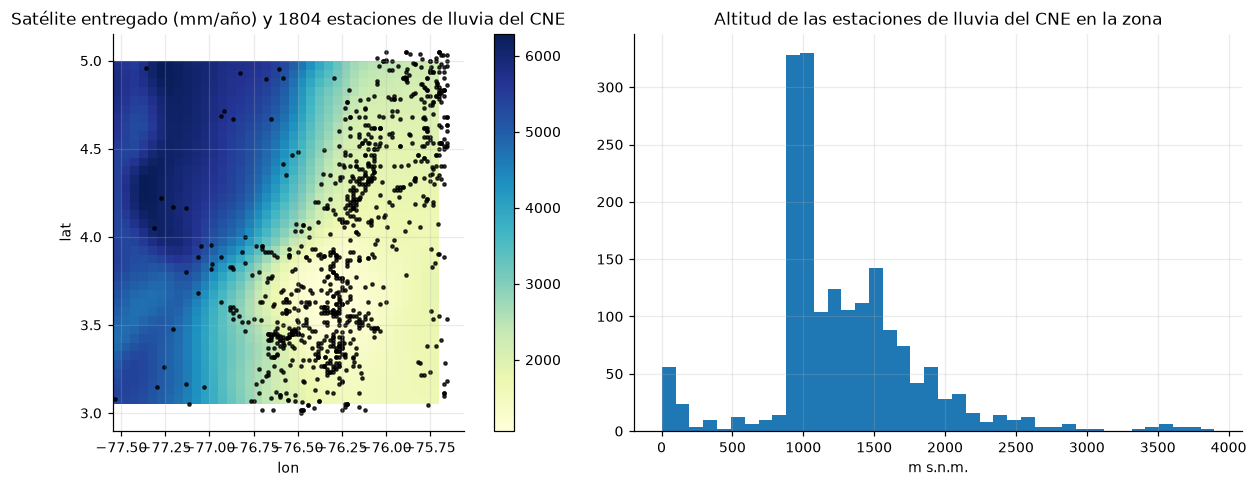

In [5]:
if cne is not None:
    with rasterio.open(sorted(SAT_DIR.glob("ppt*.tif"))[0]) as r:
        b = r.bounds
    sat = np.stack([rasterio.open(p).read(1).astype(float) for p in sorted(SAT_DIR.glob("ppt*.tif"))])
    clim = sat[:23*72].reshape(23, 72, 39, 37).sum(1).mean(0)       # 1981‑2003, periodo del proyecto
    pl = cne[cne.categoria.str.contains("Pluvio|Climat", na=False)]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    im = ax[0].imshow(clim, extent=[b.left, b.right, b.bottom, b.top], cmap="YlGnBu", origin="upper")
    ax[0].scatter(pl.longitud, pl.latitud, s=4, c="k", alpha=.5)
    ax[0].set(title=f"Satélite entregado (mm/año) y {len(pl)} estaciones de lluvia del CNE", xlabel="lon", ylabel="lat")
    plt.colorbar(im, ax=ax[0])
    ax[1].hist(pl.altitud.astype(float), bins=40); ax[1].set(title="Altitud de las estaciones de lluvia del CNE en la zona", xlabel="m s.n.m.")
    plt.tight_layout(); plt.show()

## 3. ¿El satélite entregado es CHIRPS v2? Comparación con el producto original

La malla del satélite entregado (0,05°, lon −77,55 a −75,70, lat 3,05 a 5,00) coincide con la de **CHIRPS** (*Climate Hazards Group InfraRed Precipitation with Station data*, UCSB). Se descargó CHIRPS v2.0 pentadal para la misma ventana y periodo y se comparan:

- **ubicación y calendario** (¿mismos píxeles, mismas péntadas?);
- **climatología espacial** y diferencia entre productos;
- **variación año a año**, junto con las estaciones.

In [6]:
f_bin = DW / "chirps_v2_valle_1981_2013.bin"; f_keys = DW / "chirps_v2_valle_1981_2013_claves.txt"
HAY_CHIRPS = f_bin.exists() and f_keys.exists()
if HAY_CHIRPS:
    claves = f_keys.read_text().split()
    ch = np.fromfile(f_bin, dtype="<f4").reshape(len(claves), 39, 37)
    ch[ch < -100] = np.nan                                  # -9999 = océano (sin dato en CHIRPS)
    cm = pd.DataFrame([c.split(".") for c in claves], columns=["anio", "mes", "p"]).astype(int)
    cm["pentada"] = (cm.mes - 1) * 6 + cm.p
    print(f"CHIRPS v2: {ch.shape[0]} péntadas; años {cm.anio.min()}–{cm.anio.max()}; "
          f"píxeles de océano: {int(np.isnan(ch[0]).sum())}")
else:
    print("Falta el CHIRPS v2 en datos_web/ (mover desde Descargas).")

CHIRPS v2: 2376 péntadas; años 1981–2013; píxeles de océano: 90


In [7]:
if HAY_CHIRPS:
    tifs = sorted(SAT_DIR.glob("ppt*.tif"))
    pm = pd.DataFrame({"anio": [int(p.stem[3:7]) for p in tifs], "pentada": [int(p.stem[7:9]) for p in tifs]})
    pr = np.stack([rasterio.open(p).read(1).astype(float) for p in tifs])
    # emparejar por (año, péntada)
    j = cm.reset_index().merge(pm.reset_index(), on=["anio", "pentada"], suffixes=("_ch", "_pr"))
    j = j[j.anio <= 2003].reset_index(drop=True)                 # periodo del proyecto: 1981–2003
    A, B = ch[j.index_ch.values], pr[j.index_pr.values]
    tierra = ~np.isnan(ch[0])
    B_m = np.where(tierra, B, np.nan)
    print(f"Péntadas emparejadas: {len(j)}")

    # correlación temporal por píxel y con desfases de ±2 péntadas (prueba de calendario)
    def corr_t(x, y):
        x = x - np.nanmean(x, 0); y = y - np.nanmean(y, 0)
        return np.nansum(x*y, 0) / np.sqrt(np.nansum(x*x, 0) * np.nansum(y*y, 0))
    r_pix = corr_t(A, B_m)
    serie_ch, serie_pr = np.nanmean(A, (1, 2)), np.nanmean(B_m, (1, 2))
    for lag in [-2, -1, 0, 1, 2]:
        print(f"desfase {lag:+d} péntadas: r(media regional) = {pd.Series(serie_pr).corr(pd.Series(serie_ch).shift(lag)):.3f}")
    print(f"Correlación temporal mediana por píxel: {np.nanmedian(r_pix):.2f}")

Péntadas emparejadas: 1656
desfase -2 péntadas: r(media regional) = 0.326
desfase -1 péntadas: r(media regional) = 0.382
desfase +0 péntadas: r(media regional) = 0.792
desfase +1 péntadas: r(media regional) = 0.391
desfase +2 péntadas: r(media regional) = 0.320
Correlación temporal mediana por píxel: 0.73


C:\Users\Administrador\AppData\Local\Temp\ipykernel_14740\455943349.py:15: RuntimeWarning: Mean of empty slice
  x = x - np.nanmean(x, 0); y = y - np.nanmean(y, 0)
C:\Users\Administrador\AppData\Local\Temp\ipykernel_14740\455943349.py:16: RuntimeWarning: invalid value encountered in divide
  return np.nansum(x*y, 0) / np.sqrt(np.nansum(x*x, 0) * np.nansum(y*y, 0))


C:\Users\Administrador\AppData\Local\Temp\ipykernel_14740\3428746180.py:10: RuntimeWarning: invalid value encountered in divide
  im = ax[2].imshow(100*(clim_pr/clim_ch - 1), extent=ext, cmap="RdBu", vmin=-40, vmax=40)


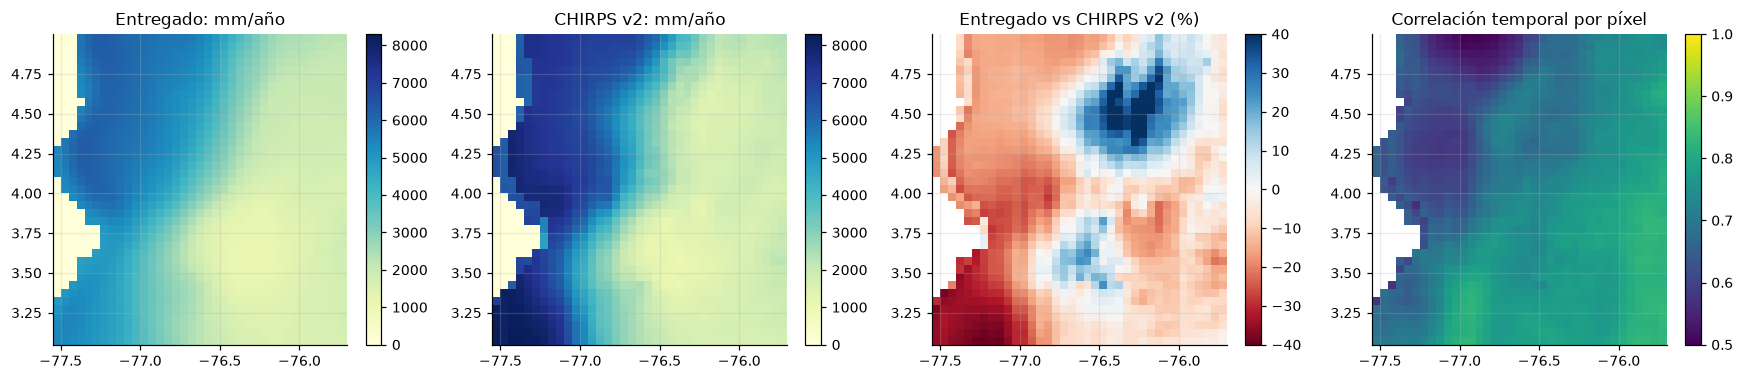

Diferencia media (tierra): -13.0 %
Máximo CHIRPS v2: 495 mm/péntada | celdas > 200 en CHIRPS v2: 27089 | celdas = 200 en el entregado: 5138


In [8]:
if HAY_CHIRPS:
    n_anios = j.anio.nunique()
    clim_ch = np.nansum(A, 0) / n_anios; clim_pr = np.nansum(B_m, 0) / n_anios
    with rasterio.open(tifs[0]) as r: b = r.bounds
    ext = [b.left, b.right, b.bottom, b.top]
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
    vmax = np.nanmax([clim_ch, clim_pr])
    for a, m, t in [(ax[0], clim_pr, "Entregado"), (ax[1], clim_ch, "CHIRPS v2")]:
        im = a.imshow(m, extent=ext, cmap="YlGnBu", vmin=0, vmax=vmax); a.set_title(f"{t}: mm/año"); plt.colorbar(im, ax=a, shrink=.8)
    im = ax[2].imshow(100*(clim_pr/clim_ch - 1), extent=ext, cmap="RdBu", vmin=-40, vmax=40)
    ax[2].set_title("Entregado vs CHIRPS v2 (%)"); plt.colorbar(im, ax=ax[2], shrink=.8)
    im = ax[3].imshow(r_pix, extent=ext, cmap="viridis", vmin=.5, vmax=1); ax[3].set_title("Correlación temporal por píxel"); plt.colorbar(im, ax=ax[3], shrink=.8)
    plt.tight_layout(); plt.show()
    print(f"Diferencia media (tierra): {100*(np.nansum(clim_pr)/np.nansum(clim_ch)-1):.1f} %")
    print(f"Máximo CHIRPS v2: {np.nanmax(A):.0f} mm/péntada | celdas > 200 en CHIRPS v2: {(A > 200).sum()} "
          f"| celdas = 200 en el entregado: {(B == 200).sum()}")

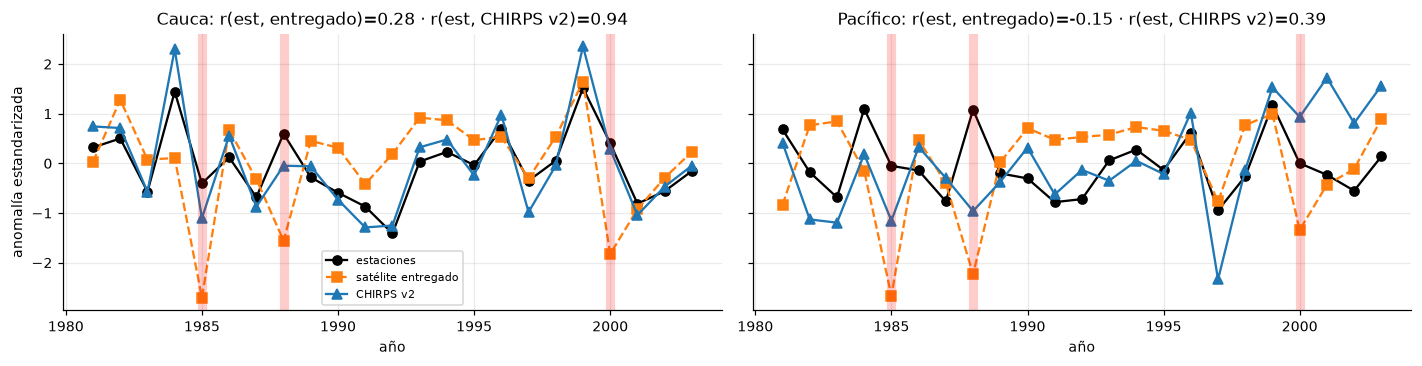

estaciones          entregado       CHIRPS v2      
          Cauca Pacífico  Pacífico Cauca  Pacífico Cauca
1985      -0.40    -0.05     -2.67 -2.70     -1.15 -1.10
1988       0.60     1.08     -2.23 -1.56     -0.96 -0.05
1997      -0.35    -0.95     -0.77 -0.30     -2.34 -0.98
2000       0.41     0.00     -1.34 -1.83      0.94  0.29

In [9]:
if HAY_CHIRPS:
    oeste = (np.arange(37) * .05 + b.left + .025) < -76.8
    def anual(cubo, anio_col):
        df = pd.DataFrame({"anio": anio_col, "Pacífico": np.nanmean(cubo[:, :, oeste], (1, 2)),
                           "Cauca": np.nanmean(cubo[:, :, ~oeste], (1, 2))})
        g = df.groupby("anio"); t = g.mean()[g.size() >= 60]          # años con ≥60 péntadas
        return (t - t.mean()) / t.std()
    z_ch = anual(A, j.anio.values); z_pr = anual(B_m, j.anio.values)

    # anomalía de las estaciones (mismo cálculo que en el notebook 01)
    val = pd.read_csv(OUT / "pares_estacion_anio_validos_preliminar.csv")
    x = raw[raw.YEAR.between(1981, 2003) & (raw.VALUE <= 500)].merge(val, on=["STATION_ID", "YEAR"])
    tot = x.groupby(["STATION_ID", "YEAR", "cuenca"]).VALUE.mean().rename("v").reset_index()
    tot["z"] = tot.groupby("STATION_ID").v.transform(lambda s: (s - s.mean()) / s.std())
    z_est = tot.groupby(["YEAR", "cuenca"]).z.median().unstack()

    fig, ax = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True)
    for a, cu in zip(ax, ["Cauca", "Pacífico"]):
        a.plot(z_est.index, z_est[cu], "o-", c="k", label="estaciones")
        a.plot(z_pr.index, z_pr[cu], "s--", c="C1", label="satélite entregado")
        a.plot(z_ch.index, z_ch[cu], "^-", c="C0", label="CHIRPS v2")
        for y in [1985, 1988, 2000]: a.axvline(y, color="red", alpha=.2, lw=6)
        cc = pd.concat([z_est[cu], z_pr[cu], z_ch[cu]], axis=1, keys=["est", "ent", "chv2"]).dropna().corr()
        a.set(title=f"{cu}: r(est, entregado)={cc.loc['est','ent']:.2f} · r(est, CHIRPS v2)={cc.loc['est','chv2']:.2f}", xlabel="año")
    ax[0].set_ylabel("anomalía estandarizada"); ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()
    tabla = pd.concat({"estaciones": z_est, "entregado": z_pr, "CHIRPS v2": z_ch}, axis=1)
    display(tabla.loc[[1985, 1988, 1997, 2000]].round(2))
    tabla.to_csv(OUT / "anomalias_anuales_est_entregado_chirpsv2.csv")

**Lectura.**
- **Mismo producto de base, distinta versión.** El satélite entregado tiene la misma malla y el mismo calendario de péntadas que CHIRPS v2: la correlación con la media regional es máxima sin desfase. Pero no son iguales: es más suave, en promedio ~13 % más seco (1981–2003), el océano viene rellenado y está recortado en 200 mm/péntada (CHIRPS v2 llega a ~500 en la costa).
- **Año a año, CHIRPS v2 sigue a las estaciones y el entregado no.** En el valle, la anomalía anual de CHIRPS v2 se correlaciona ≈0,94 con la de las estaciones (1981–2003), frente a ≈0,28 del entregado. En el Pacífico, con pocas estaciones, ambas correlaciones son bajas.
- **Los años sospechosos:** **2000** es normal en CHIRPS v2 y en las estaciones, y muy seco solo en el entregado. **1988** en el valle es casi normal en CHIRPS v2. **1985** aparece seco también en CHIRPS v2, aunque menos que en el entregado, y las estaciones no lo muestran. El déficit de 2000, y buena parte de los de 1985 y 1988, son **propios del producto entregado**.
- **Advertencia importante:** CHIRPS v2 incorpora datos de pluviómetros en su cálculo (la "S" de *with Station data*), posiblemente algunas de estas mismas estaciones. Su alta correlación con las estaciones es en parte **por construcción**, así que no es una fuente independiente para validar. Por eso no reemplaza al satélite del enunciado.

## 3b. NASA POWER (MERRA‑2) como tercera fuente de referencia

NASA POWER entrega precipitación diaria corregida (`PRECTOTCORR`, mm/día) del **reanálisis MERRA‑2**, a su resolución nativa de 0,5° × 0,625° (~55 × 70 km). Se descargaron los 20 nodos que cubren la caja del satélite (lat 3,0–5,0; lon −77,5 a −75,625), entre 1981 y 2013, desde la API `power.larc.nasa.gov/api/temporal/daily/point`.

Qué aporta y qué no:
- Es **diario**, como las estaciones, y es un modelo físico (reanálisis), **independiente** del producto satelital.
- Su malla es ~10 veces más gruesa que la del satélite: no resuelve el valle frente a las cordilleras. Cada celda promedia montaña y valle (la altitud de celda del nodo cercano a Cali es ~2 100 m, cuando Cali está a ~1 000 m).
- Sirve como referencia de **variabilidad interanual y ciclo anual regional**, no para emparejar estación por estación.

Valores de relleno (-999): 0


elev_celda_m                         mm_anio                        
lon      -77.500 -76.875 -76.250 -75.625 -77.500 -76.875 -76.250 -75.625
lat                                                                     
3.0        183.0  1163.0  2321.0  1567.0  1825.0  1009.0  1010.0  1124.0
3.5         79.0   794.0  2112.0  1705.0  1981.0  1093.0  1073.0  1164.0
4.0         19.0   508.0  1698.0  2030.0  2424.0  1665.0  1596.0  1536.0
4.5         12.0   327.0  1116.0  2267.0  3414.0  2866.0  2699.0  2235.0
5.0         21.0   204.0  1019.0  2138.0  4639.0  4225.0  3872.0  2887.0

C:\Users\Administrador\AppData\Local\Temp\ipykernel_14740\3147075401.py:11: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  clim = (npw.assign(doy=npw.fecha.dt.dayofyear.clip(upper=365))


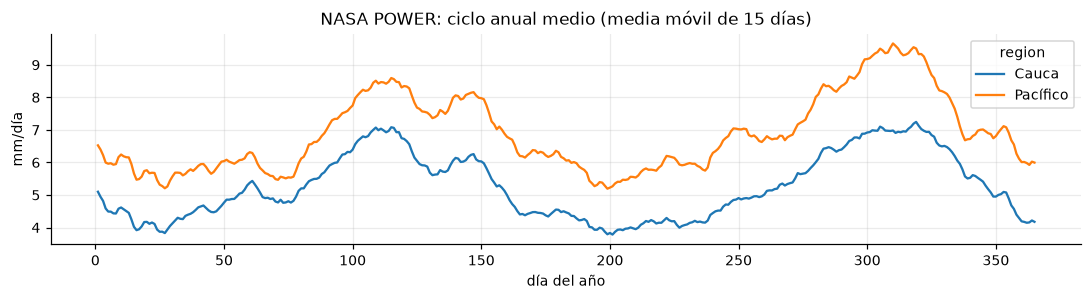

In [10]:
f_np = DW / "nasa_power_PRECTOTCORR_valle_1981_2013.csv"
if f_np.exists():
    npw = pd.read_csv(f_np, dtype={"fecha": str})
    npw["fecha"] = pd.to_datetime(npw.fecha); npw["anio"] = npw.fecha.dt.year
    print("Valores de relleno (-999):", int((npw.PRECTOTCORR_mm_dia <= -900).sum()))
    npw = npw[npw.PRECTOTCORR_mm_dia > -900]
    npw["region"] = np.where(npw.lon <= -76.875, "Pacífico", "Cauca")
    nodos = npw.groupby(["lat", "lon"]).agg(elev_celda_m=("elev_celda_m", "first"),
                                            mm_anio=("PRECTOTCORR_mm_dia", lambda v: v.mean() * 365.25)).round(0)
    display(nodos.unstack("lon"))
    clim = (npw.assign(doy=npw.fecha.dt.dayofyear.clip(upper=365))
               .groupby(["region", "doy"]).PRECTOTCORR_mm_dia.mean().unstack(0))
    fig, ax = plt.subplots(figsize=(10, 2.8))
    clim.rolling(15, center=True, min_periods=1).mean().plot(ax=ax)
    ax.set(title="NASA POWER: ciclo anual medio (media móvil de 15 días)", xlabel="día del año", ylabel="mm/día")
    plt.tight_layout(); plt.show()

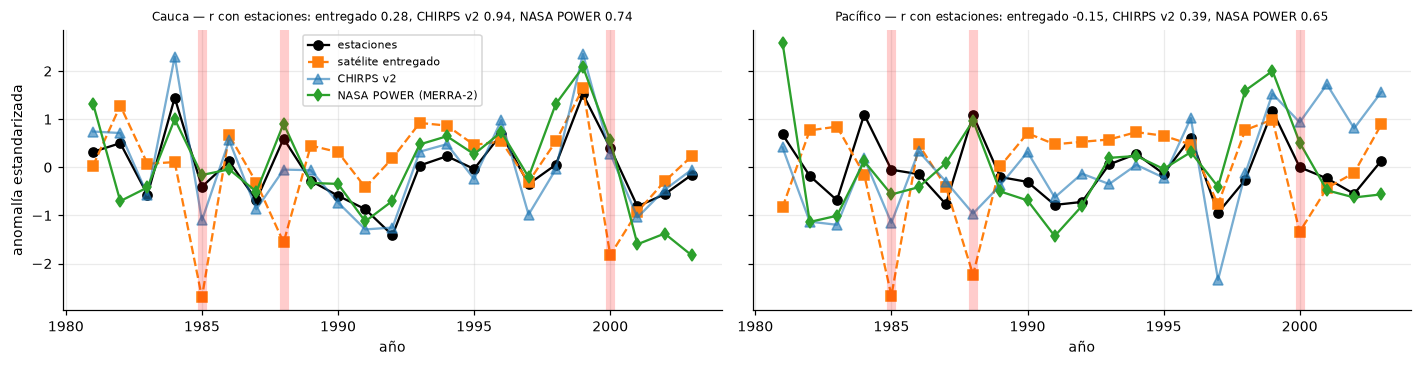

estaciones          entregado       CHIRPS v2       NASA POWER         
          Cauca Pacífico  Pacífico Cauca  Pacífico Cauca      Cauca Pacífico
1985      -0.40    -0.05     -2.67 -2.70     -1.15 -1.10      -0.16    -0.56
1988       0.60     1.08     -2.23 -1.56     -0.96 -0.05       0.91     0.97
1997      -0.35    -0.95     -0.77 -0.30     -2.34 -0.98      -0.20    -0.40
1999       1.52     1.18      0.99  1.65      1.53  2.36       2.08     2.00
2000       0.41     0.00     -1.34 -1.83      0.94  0.29       0.56     0.51

In [11]:
if f_np.exists() and HAY_CHIRPS:
    z_np = npw[npw.anio <= 2003].groupby(["anio", "region"]).PRECTOTCORR_mm_dia.mean().unstack()   # 1981–2003
    z_np = (z_np - z_np.mean()) / z_np.std()
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True)
    for a, cu in zip(ax, ["Cauca", "Pacífico"]):
        a.plot(z_est.index, z_est[cu], "o-", c="k", label="estaciones")
        a.plot(z_pr.index, z_pr[cu], "s--", c="C1", label="satélite entregado")
        a.plot(z_ch.index, z_ch[cu], "^-", c="C0", alpha=.6, label="CHIRPS v2")
        a.plot(z_np.index, z_np[cu], "d-", c="C2", label="NASA POWER (MERRA‑2)")
        for y in [1985, 1988, 2000]: a.axvline(y, color="red", alpha=.2, lw=6)
        cc = pd.concat([z_est[cu], z_pr[cu], z_ch[cu], z_np[cu]], axis=1, keys=["est", "ent", "chv2", "np"]).dropna().corr()
        a.set_title(f"{cu} — r con estaciones: entregado {cc.loc['est','ent']:.2f}, CHIRPS v2 {cc.loc['est','chv2']:.2f}, "
                    f"NASA POWER {cc.loc['est','np']:.2f}", fontsize=8)
        a.set_xlabel("año")
    ax[0].set_ylabel("anomalía estandarizada"); ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()
    tabla4 = pd.concat({"estaciones": z_est, "entregado": z_pr, "CHIRPS v2": z_ch, "NASA POWER": z_np}, axis=1)
    display(tabla4.loc[[1985, 1988, 1997, 1999, 2000]].round(2))
    tabla4.to_csv(OUT / "anomalias_anuales_4_fuentes.csv")

**Lectura de NASA POWER.**
- **Confirmación independiente de los años sospechosos.** Año a año (1981–2003), NASA POWER se correlaciona ≈0,74 con las estaciones en el valle y ≈0,65 en el Pacífico (el satélite entregado: ≈0,28 y ≈−0,15). Como las estaciones, marca **1988 y 2000 como años húmedos** (La Niña) y 1985 como normal. Los déficits de esos años en el satélite entregado **no son clima**: son un defecto del producto.
- **Subestima la costa Pacífica**: ~1 800–2 400 mm/año en los nodos costeros del sur, frente a >5 000 en el satélite y en las estaciones del Pacífico. Su celda gruesa no capta la lluvia orográfica de la costa.
- Reproduce el **gradiente oeste‑este** y el **ciclo bimodal** del valle, pero con mucho menos detalle espacial.
- Uso propuesto: **fuente de contraste** en el informe (años sospechosos y ciclo anual regional). **No** sirve para rellenar huecos de estaciones: su celda de ~55 km mezcla valle y montaña, e imputar con ella metería un sesgo de escala justo en lo que se quiere comparar.

## 4. Conclusiones y decisiones

- **ONI**: descargado y resumido por año (`eda_fase0/oni_anual_fase.csv`); listo para `z` y para el análisis por fase.
- **Coordenadas y altitud: no se pueden obtener de fuentes públicas** porque los códigos del proyecto no corresponden al catálogo oficial. Hay que pedir al docente la tabla `STATION_ID → latitud, longitud, altitud` (o el nombre de cada estación, para cruzarlo con el CNE).
- **Relleno de huecos desde la web: no viable** para 1981–2003 (datos públicos solo desde 2017 y sin mapa de códigos). Se mantiene la estrategia del notebook 01: marcar faltantes, criterio de cobertura y suavizado B‑spline sin imputar.
- **El satélite entregado no es CHIRPS v2.** Comparte malla y calendario de péntadas, pero es más suave, ~14 % más seco, tiene el océano rellenado, está recortado en 200 mm/péntada y presenta déficits en 1985, 1988 y 2000 que **las estaciones no muestran y CHIRPS v2 no muestra (2000) o muestra atenuados (1985, 1988)**. Para el proyecto:
  1. el análisis principal se hace con el satélite **entregado** (es el dato del enunciado);
  2. CHIRPS v2 sirve como **análisis de sensibilidad**: si una conclusión sobre el sesgo satelital cambia al usar CHIRPS v2, hay que decirlo;
  3. 1985, 1988 y 2000 se tratan como **años sospechosos del producto** (NASA POWER, independiente de los pluviómetros, confirma que 1988 y 2000 fueron húmedos) (candidatos a atípicos en el boxplot funcional), con decisión documentada.